<a href="https://colab.research.google.com/github/Alex-Siauw/California-Dermatologist-Access/blob/main/dermscali.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#California Dermatologist Density Project

Given my interest in health equity (especially in dermatology!) and how I recently moved to California, I wanted to investigate: How does dermatologist density vary across California counties, and how is it associated with county income?

#Data Sources

For this project, I derived county-level and population data from HRSA Area Health Resources Files (AHRF) and median household income data from the U.S. Census American Community Survey (ACS). Since it was the most recent year available, 2023 was used to standardize.

#Loading Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt



#Dermatologist Data

In [ ]:
df = pd.read_csv("/content/AHRF2025hp.csv")

In [ ]:
df.head()

,fips_st_cnty,cnty_name_st_abbrev,phys_nf_prim_care_pc_exc_rsdt_23,phys_nf_prim_care_pc_exc_rsdt_22,phys_nf_prim_care_pc_rsdnt_23,phys_nf_prim_care_pc_rsdnt_22,md_nf_prim_care_pc_excl_rsdnt_23,md_nf_prim_care_pc_excl_rsdnt_22,md_nf_prim_care_pc_rsdnt_23,md_nf_prim_care_pc_rsdnt_22,...,tot_md_do_plas_surg_23,tot_md_do_anat_path_23,tot_md_do_pulm_dis_23,tot_md_do_radlgy_23,tot_md_do_rad_oncolgy_23,tot_md_do_thor_surg_23,tot_md_do_transpl_surg_23,tot_md_do_urolgy_23,tot_md_do_unspec_23,tot_md_do_vasc_med_23
0,1001,"Autauga, AL",22.0,25.0,1.0,1.0,21.0,24.0,1.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1003,"Baldwin, AL",172.0,160.0,64.0,55.0,151.0,144.0,50.0,41.0,...,5.0,11.0,8.0,5.0,2.0,2.0,0.0,8.0,7.0,0.0
2,1005,"Barbour, AL",7.0,8.0,1.0,0.0,6.0,7.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1007,"Bibb, AL",26.0,21.0,21.0,17.0,23.0,18.0,11.0,12.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1009,"Blount, AL",10.0,12.0,1.0,0.0,10.0,12.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
[col for col in df.columns if "derm" in col.lower()]

['md_nf_derm_23',
 'md_nf_derm_22',
 'md_nf_derm_all_pc_23',
 'md_nf_derm_all_pc_22',
 'md_nf_derm_pc_ofc_23',
 'md_nf_derm_pc_ofc_22',
 'md_nf_derm_pc_rsdnt_23',
 'md_nf_derm_pc_rsdnt_22',
 'md_nf_derm_pc_hosp_ft_23',
 'md_nf_derm_pc_hosp_ft_22',
 'md_nf_derm_admin_23',
 'md_nf_derm_admin_22',
 'md_nf_derm_teach_23',
 'md_nf_derm_teach_22',
 'md_nf_derm_resrch_23',
 'md_nf_derm_resrch_22',
 'md_nf_derm_oth_23',
 'md_nf_derm_oth_22',
 'md_nf_derm_lt35_23',
 'md_nf_derm_lt35_22',
 'md_nf_derm_35_44_23',
 'md_nf_derm_35_44_22',
 'md_nf_derm_45_54_23',
 'md_nf_derm_45_54_22',
 'md_nf_derm_55_64_23',
 'md_nf_derm_55_64_22',
 'md_nf_derm_65_74_23',
 'md_nf_derm_65_74_22',
 'md_nf_derm_ge75_23',
 'md_nf_derm_ge75_22',
 'tot_md_do_derm_23']

In [ ]:
ca = df[
    df["cnty_name_st_abbrev"].str.endswith(", CA")
].copy()


In [ ]:
ca.shape

(58, 1927)

In [ ]:
derm_ca = ca[
    ["fips_st_cnty", "cnty_name_st_abbrev", "md_nf_derm_23"]
].copy()

In [ ]:
derm_ca = derm_ca.rename(columns={
    "fips_st_cnty": "fips",
    "cnty_name_st_abbrev": "county",
    "md_nf_derm_23": "dermatologists"
})

In [ ]:

derm_ca.head()

,fips,county,dermatologists
188,6001,"Alameda, CA",67.0
189,6003,"Alpine, CA",0.0
190,6005,"Amador, CA",0.0
191,6007,"Butte, CA",3.0
192,6009,"Calaveras, CA",0.0


In [ ]:
derm_ca["dermatologists"].isna().sum()

np.int64(0)

In [ ]:
derm_ca["dermatologists"].describe()

,dermatologists
count,58.000000
mean,34.137931
std,81.587419
min,0.000000
25%,0.000000
50%,3.500000
75%,27.250000
max,504.000000


In [ ]:
derm_ca.sort_values(
    "dermatologists",
    ascending=False
).head(10)

,fips,county,dermatologists
206,6037,"Los Angeles, CA",504.0
217,6059,"Orange, CA",252.0
224,6073,"San Diego, CA",217.0
225,6075,"San Francisco, CA",145.0
230,6085,"Santa Clara, CA",136.0
228,6081,"San Mateo, CA",123.0
221,6067,"Sacramento, CA",91.0
194,6013,"Contra Costa, CA",70.0
188,6001,"Alameda, CA",67.0
208,6041,"Marin, CA",42.0


#Population Data

In [ ]:
pop = pd.read_csv("/content/AHRF2025pop.csv")

In [ ]:
pop.head()

,fips_st_cnty,cnty_name_st_abbrev,popn_est_24,popn_est_23,cens_popn_20,cens_popn_10,popn_23,popn_22,popn_mal_23,popn_mal_22,...,cens_rural_hous_units_20,cens_rural_hous_units_10,occd_hous_no_fuel_used_23,occd_hous_no_fuel_used_22,occd_hous_phone_svc_23,occd_hous_phone_svc_22,occd_hous_no_fuel_used_pct_23,occd_hous_no_fuel_used_pct_22,occd_hous_phone_svc_pct_23,occd_hous_phone_svc_pct_22
0,1001,"Autauga, AL",61464.0,60342.0,58805.0,54571.0,60342.0,59759.0,29277.0,29105.0,...,9991.0,9494.0,75.0,88.0,22399.0,22157.0,0.3,0.4,99.4,99.3
1,1003,"Baldwin, AL",261608.0,253507.0,231767.0,182265.0,253507.0,246435.0,123497.0,120164.0,...,40740.0,43269.0,644.0,648.0,93787.0,89832.0,0.7,0.7,99.1,98.9
2,1005,"Barbour, AL",24358.0,24585.0,25223.0,27457.0,24585.0,24706.0,13066.0,13064.0,...,7538.0,7836.0,72.0,57.0,8708.0,8637.0,0.8,0.6,95.9,95.8
3,1007,"Bibb, AL",22258.0,21868.0,22293.0,22915.0,21868.0,22005.0,11530.0,11775.0,...,9002.0,6832.0,79.0,48.0,7567.0,7091.0,1.0,0.7,99.9,98.3
4,1009,"Blount, AL",60163.0,59816.0,59134.0,57322.0,59816.0,59512.0,29756.0,29583.0,...,22337.0,21500.0,139.0,112.0,21690.0,21338.0,0.6,0.5,98.7,98.7


In [ ]:
[col for col in pop.columns if "pop" in col.lower()]

['popn_est_24',
 'popn_est_23',
 'cens_popn_20',
 'cens_popn_10',
 'popn_23',
 'popn_22',
 'popn_mal_23',
 'popn_mal_22',
 'popn_fem_23',
 'popn_fem_22',
 'popn_mal_wh_23',
 'popn_mal_wh_22',
 'popn_fem_wh_23',
 'popn_fem_wh_22',
 'popn_mal_nhsp_wh_23',
 'popn_mal_nhsp_wh_22',
 'popn_fem_nhsp_wh_23',
 'popn_fem_nhsp_wh_22',
 'popn_mal_hsp_wh_23',
 'popn_mal_hsp_wh_22',
 'popn_fem_hsp_wh_23',
 'popn_fem_hsp_wh_22',
 'popn_mal_bl_23',
 'popn_mal_bl_22',
 'popn_fem_bl_23',
 'popn_fem_bl_22',
 'popn_mal_nhsp_bl_23',
 'popn_mal_nhsp_bl_22',
 'popn_fem_nhsp_bl_23',
 'popn_fem_nhsp_bl_22',
 'popn_mal_hsp_bl_23',
 'popn_mal_hsp_bl_22',
 'popn_fem_hsp_bl_23',
 'popn_fem_hsp_bl_22',
 'popn_mal_aian_23',
 'popn_mal_aian_22',
 'popn_fem_aian_23',
 'popn_fem_aian_22',
 'popn_mal_asn_23',
 'popn_mal_asn_22',
 'popn_mal_nhpi_23',
 'popn_mal_nhpi_22',
 'popn_fem_asn_23',
 'popn_fem_asn_22',
 'popn_fem_nhpi_23',
 'popn_fem_nhpi_22',
 'popn_mal_2race_23',
 'popn_mal_2race_22',
 'popn_fem_2race_23',
 'po

Population Data

In [ ]:
pop = pd.read_csv("/content/AHRF2025pop.csv")

In [ ]:
pop.head()

,fips_st_cnty,cnty_name_st_abbrev,popn_est_24,popn_est_23,cens_popn_20,cens_popn_10,popn_23,popn_22,popn_mal_23,popn_mal_22,...,cens_rural_hous_units_20,cens_rural_hous_units_10,occd_hous_no_fuel_used_23,occd_hous_no_fuel_used_22,occd_hous_phone_svc_23,occd_hous_phone_svc_22,occd_hous_no_fuel_used_pct_23,occd_hous_no_fuel_used_pct_22,occd_hous_phone_svc_pct_23,occd_hous_phone_svc_pct_22
0,1001,"Autauga, AL",61464.0,60342.0,58805.0,54571.0,60342.0,59759.0,29277.0,29105.0,...,9991.0,9494.0,75.0,88.0,22399.0,22157.0,0.3,0.4,99.4,99.3
1,1003,"Baldwin, AL",261608.0,253507.0,231767.0,182265.0,253507.0,246435.0,123497.0,120164.0,...,40740.0,43269.0,644.0,648.0,93787.0,89832.0,0.7,0.7,99.1,98.9
2,1005,"Barbour, AL",24358.0,24585.0,25223.0,27457.0,24585.0,24706.0,13066.0,13064.0,...,7538.0,7836.0,72.0,57.0,8708.0,8637.0,0.8,0.6,95.9,95.8
3,1007,"Bibb, AL",22258.0,21868.0,22293.0,22915.0,21868.0,22005.0,11530.0,11775.0,...,9002.0,6832.0,79.0,48.0,7567.0,7091.0,1.0,0.7,99.9,98.3
4,1009,"Blount, AL",60163.0,59816.0,59134.0,57322.0,59816.0,59512.0,29756.0,29583.0,...,22337.0,21500.0,139.0,112.0,21690.0,21338.0,0.6,0.5,98.7,98.7


In [ ]:
[col for col in pop.columns if "pop" in col.lower()]

['popn_est_24',
 'popn_est_23',
 'cens_popn_20',
 'cens_popn_10',
 'popn_23',
 'popn_22',
 'popn_mal_23',
 'popn_mal_22',
 'popn_fem_23',
 'popn_fem_22',
 'popn_mal_wh_23',
 'popn_mal_wh_22',
 'popn_fem_wh_23',
 'popn_fem_wh_22',
 'popn_mal_nhsp_wh_23',
 'popn_mal_nhsp_wh_22',
 'popn_fem_nhsp_wh_23',
 'popn_fem_nhsp_wh_22',
 'popn_mal_hsp_wh_23',
 'popn_mal_hsp_wh_22',
 'popn_fem_hsp_wh_23',
 'popn_fem_hsp_wh_22',
 'popn_mal_bl_23',
 'popn_mal_bl_22',
 'popn_fem_bl_23',
 'popn_fem_bl_22',
 'popn_mal_nhsp_bl_23',
 'popn_mal_nhsp_bl_22',
 'popn_fem_nhsp_bl_23',
 'popn_fem_nhsp_bl_22',
 'popn_mal_hsp_bl_23',
 'popn_mal_hsp_bl_22',
 'popn_fem_hsp_bl_23',
 'popn_fem_hsp_bl_22',
 'popn_mal_aian_23',
 'popn_mal_aian_22',
 'popn_fem_aian_23',
 'popn_fem_aian_22',
 'popn_mal_asn_23',
 'popn_mal_asn_22',
 'popn_mal_nhpi_23',
 'popn_mal_nhpi_22',
 'popn_fem_asn_23',
 'popn_fem_asn_22',
 'popn_fem_nhpi_23',
 'popn_fem_nhpi_22',
 'popn_mal_2race_23',
 'popn_mal_2race_22',
 'popn_fem_2race_23',
 'po

In [ ]:
pop_ca = pop[
    pop["cnty_name_st_abbrev"].str.endswith(", CA")
].copy()

In [ ]:
pop_ca = pop_ca[
    ["fips_st_cnty", "cnty_name_st_abbrev", "popn_est_23"]
].copy()

In [ ]:
op_ca = pop_ca.rename(columns={
    "fips_st_cnty": "fips",
    "cnty_name_st_abbrev": "county",
    "popn_est_23": "population"
})

In [ ]:
pop_ca.head()

,fips_st_cnty,cnty_name_st_abbrev,popn_est_23
188,6001,"Alameda, CA",1622188.0
189,6003,"Alpine, CA",1141.0
190,6005,"Amador, CA",41811.0
191,6007,"Butte, CA",207172.0
192,6009,"Calaveras, CA",46565.0


In [ ]:
derm_ca = derm_ca.rename(columns={
    "fips_st_cnty": "fips",
    "cnty_name_st_abbrev": "county",
    "md_nf_derm_23": "dermatologists"
})

In [ ]:
pop_ca = pop_ca.rename(columns={
    "fips_st_cnty": "fips",
    "cnty_name_st_abbrev": "county",
    "popn_est_23": "population"
})

In [ ]:
analysis = derm_ca.merge(
    pop_ca,
    on=["fips", "county"],
    how="left"
)

#Construct Dermatologist Density

In [ ]:
analysis["derms_per_100k"] = (
    analysis["dermatologists"] /
    analysis["population"] *
    100000
)

In [ ]:
analysis[
    ["county", "dermatologists", "population", "derms_per_100k"]
].head(10)

,county,dermatologists,population,derms_per_100k
0,"Alameda, CA",67.0,1622188.0,4.130224
1,"Alpine, CA",0.0,1141.0,0.000000
2,"Amador, CA",0.0,41811.0,0.000000
3,"Butte, CA",3.0,207172.0,1.448072
4,"Calaveras, CA",0.0,46565.0,0.000000
5,"Colusa, CA",0.0,22037.0,0.000000
6,"Contra Costa, CA",70.0,1155025.0,6.060475
7,"Del Norte, CA",0.0,26589.0,0.000000
8,"El Dorado, CA",5.0,192215.0,2.601254
9,"Fresno, CA",20.0,1017162.0,1.966255


##Descriptive Results


Which counties have the highest dermatolgist densities?


In [ ]:
analysis.sort_values(
    "derms_per_100k",
    ascending=False
)[["county", "derms_per_100k"]].head(10)

,county,derms_per_100k
37,"San Francisco, CA",17.923628
40,"San Mateo, CA",16.933915
20,"Marin, CA",16.508980
29,"Orange, CA",8.036342
42,"Santa Clara, CA",7.243320
36,"San Diego, CA",6.636140
30,"Placer, CA",6.610618
6,"Contra Costa, CA",6.060475
48,"Sonoma, CA",6.018945
33,"Sacramento, CA",5.743905


Which counties have the lowest dermatologist densitites?




In [ ]:
analysis.sort_values(
    "derms_per_100k",
    ascending=True
)[["county", "derms_per_100k"]].head(10)

,county,derms_per_100k
1,"Alpine, CA",0.0
2,"Amador, CA",0.0
5,"Colusa, CA",0.0
4,"Calaveras, CA",0.0
7,"Del Norte, CA",0.0
15,"Kings, CA",0.0
10,"Glenn, CA",0.0
11,"Humboldt, CA",0.0
13,"Inyo, CA",0.0
24,"Modoc, CA",0.0


#Median Household Income Data

In [ ]:
raw_income = pd.read_csv("/content/ACSDT5Y2023.B19013-2026-09-23T042430.csv")

In [ ]:
raw_income.head()

,Label (Grouping),"Alameda County, California!!Estimate","Alameda County, California!!Margin of Error","Alpine County, California!!Estimate","Alpine County, California!!Margin of Error","Amador County, California!!Estimate","Amador County, California!!Margin of Error","Butte County, California!!Estimate","Butte County, California!!Margin of Error","Calaveras County, California!!Estimate",...,"Tulare County, California!!Estimate","Tulare County, California!!Margin of Error","Tuolumne County, California!!Estimate","Tuolumne County, California!!Margin of Error","Ventura County, California!!Estimate","Ventura County, California!!Margin of Error","Yolo County, California!!Estimate","Yolo County, California!!Margin of Error","Yuba County, California!!Estimate","Yuba County, California!!Margin of Error"
0,Median household income in the past 12 months ...,"126,240","±1,364","110,781","±18,601","81,526","±7,398","68,574","±2,351","79,877",...,"69,489","±1,785","72,259","±5,678","107,327","±1,391","88,818","±3,641","73,313","±4,341"


In [ ]:
estimate_cols = [
    col for col in raw_income.columns
    if col.endswith("!!Estimate")
]

In [ ]:
len(estimate_cols)

58

In [ ]:
income = raw_income[estimate_cols].T.reset_index()

In [ ]:
income.head()

,index,0
0,"Alameda County, California!!Estimate","126,240"
1,"Alpine County, California!!Estimate","110,781"
2,"Amador County, California!!Estimate","81,526"
3,"Butte County, California!!Estimate","68,574"
4,"Calaveras County, California!!Estimate","79,877"


In [ ]:
income.columns = ["county", "median_income"]

In [ ]:
income.head()

,county,median_income
0,"Alameda County, California!!Estimate","126,240"
1,"Alpine County, California!!Estimate","110,781"
2,"Amador County, California!!Estimate","81,526"
3,"Butte County, California!!Estimate","68,574"
4,"Calaveras County, California!!Estimate","79,877"


In [ ]:
income["county"] = (
    income["county"]
    .str.replace(" County, California!!Estimate", "", regex=False)
    + ", CA"
)

In [ ]:
income.head()

,county,median_income
0,"Alameda, CA","126,240"
1,"Alpine, CA","110,781"
2,"Amador, CA","81,526"
3,"Butte, CA","68,574"
4,"Calaveras, CA","79,877"


In [ ]:
income["median_income"] = (
    income["median_income"]
    .str.replace(",", "", regex=False)
    .astype(float)
)

In [ ]:
income.head(10)

,county,median_income
0,"Alameda, CA",126240.0
1,"Alpine, CA",110781.0
2,"Amador, CA",81526.0
3,"Butte, CA",68574.0
4,"Calaveras, CA",79877.0
5,"Colusa, CA",75149.0
6,"Contra Costa, CA",125727.0
7,"Del Norte, CA",66780.0
8,"El Dorado, CA",106190.0
9,"Fresno, CA",71434.0


#Merge Final Dataset

In [ ]:
analysis = analysis.merge(
    income,
    on="county",
    how="left"
)

In [ ]:
analysis[
    ["county", "dermatologists", "population",
     "derms_per_100k", "median_income"]
].head(10)

,county,dermatologists,population,derms_per_100k,median_income
0,"Alameda, CA",67.0,1622188.0,4.130224,126240.0
1,"Alpine, CA",0.0,1141.0,0.000000,110781.0
2,"Amador, CA",0.0,41811.0,0.000000,81526.0
3,"Butte, CA",3.0,207172.0,1.448072,68574.0
4,"Calaveras, CA",0.0,46565.0,0.000000,79877.0
5,"Colusa, CA",0.0,22037.0,0.000000,75149.0
6,"Contra Costa, CA",70.0,1155025.0,6.060475,125727.0
7,"Del Norte, CA",0.0,26589.0,0.000000,66780.0
8,"El Dorado, CA",5.0,192215.0,2.601254,106190.0
9,"Fresno, CA",20.0,1017162.0,1.966255,71434.0


##Median income vs. Dermatologist Density

In [ ]:
analysis[["median_income", "derms_per_100k"]].isna().sum()

,0
median_income,0
derms_per_100k,0


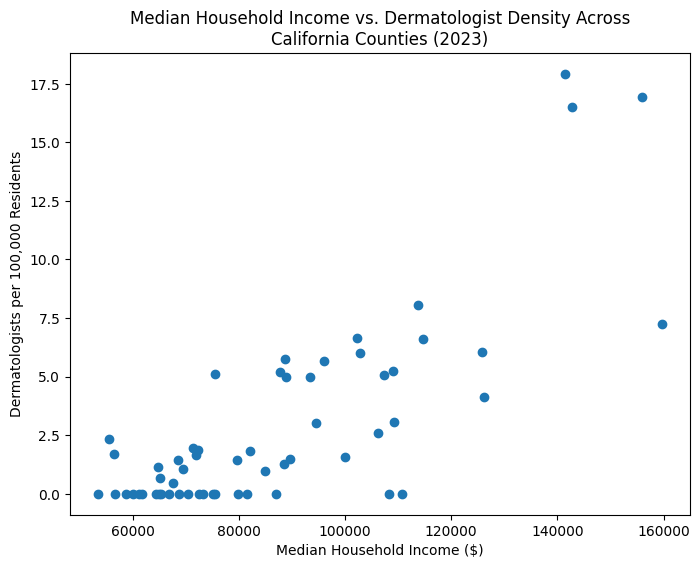

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    analysis["median_income"],
    analysis["derms_per_100k"]
)

plt.xlabel("Median Household Income ($)")
plt.ylabel("Dermatologists per 100,000 Residents")
plt.title("Median Household Income vs. Dermatologist Density Across\nCalifornia Counties (2023)")

plt.show()

##Correlation Analysis

###Pearson

In [ ]:
from scipy.stats import pearsonr

r, p = pearsonr(
    analysis["median_income"],
    analysis["derms_per_100k"]
)

print("Pearson r:", r)
print("p-value:", p)

Pearson r: 0.7842459168849762
p-value: 3.2996565118729904e-13


###Interpretation

I conducted a Pearson test to assess the strength of the correlation. An r-value of 0.784 suggests a strong positive correlation between median income and dermatologist density. The very small p-value of 3.3e-13 suggests that the results are unlikely due to random chance.

##Linear Regression

In [ ]:
analysis["income_10k"] = analysis["median_income"] / 10000

In [ ]:
import statsmodels.api as sm

X = analysis["income_10k"]
X = sm.add_constant(X)

y = analysis["derms_per_100k"]

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:         derms_per_100k   R-squared:                       0.615
Model:                            OLS   Adj. R-squared:                  0.608
Method:                 Least Squares   F-statistic:                     89.47
Date:                Wed, 23 Sep 2026   Prob (F-statistic):           3.30e-13
Time:                        05:04:20   Log-Likelihood:                -136.07
No. Observations:                  58   AIC:                             276.1
Df Residuals:                      56   BIC:                             280.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -8.0495      1.208     -6.662      0.0

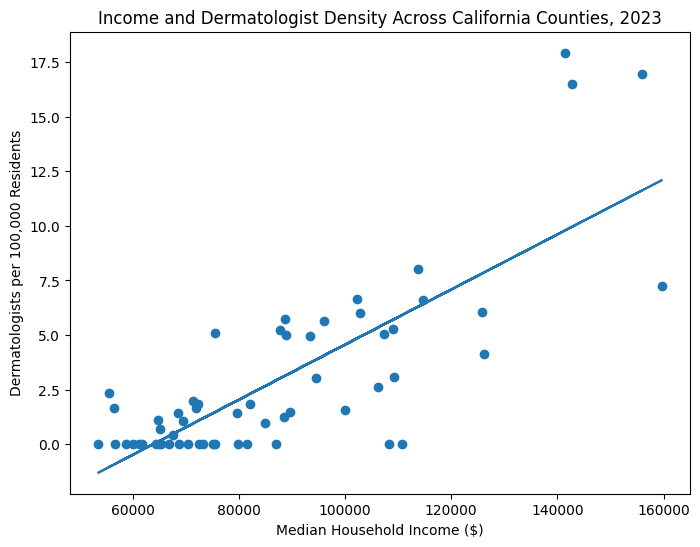

In [ ]:
import numpy as np

plt.figure(figsize=(8, 6))

plt.scatter(
    analysis["median_income"],
    analysis["derms_per_100k"]
)

m, b = np.polyfit(
    analysis["median_income"],
    analysis["derms_per_100k"],
    1
)

plt.plot(
    analysis["median_income"],
    m * analysis["median_income"] + b
)

plt.xlabel("Median Household Income ($)")
plt.ylabel("Dermatologists per 100,000 Residents")
plt.title("Income and Dermatologist Density Across California Counties (2023)")

plt.show()

Linear regression + scatterplot showcasing the relationship between median household income and dermatologist density. Each datapoint represents a California county.

###Interpretation

The linear regression showed a strong positive association between county median household income and dermatologist density. The slope of 1.261 implies that for each $10,000 increase in median household income, a county sees approximately 1.26 additional dermatologists per 100,000 residents (with a p-value < 0.001). The model had an R² of 0.615, meaning that median household income alone explained approximately 61.5% of the variation in dermatologist density across California counties. Other factors could potentially include proximity to medical centers, etc.

#Summary

Ultimately, my goal with this project was to examine how dermatologist density varies across California counties and whether it is associated with county median household income. Using 2023 HRSA AHRF and U.S. Census ACS data, I standardized dermatologist supply per 100,000 residents and analyzed the relationship using correlation and linear regression. Higher income counties were found to have substantially greater dermatologist density, and vice versa.

#Limitations

A couple of limitations should be noted. First, the dermatologist variable includes non-federal M.D. dermatologists and may exclude D.O. or federally employed physicians. Dermatologist density is also only a proxy for access. Finally, the observed association with income does not inherently establish causation, and may be influenced by other county-level factors apart from median household income alone.